# Module 01 — Anatomy of One LLM Training Step

This notebook follows one complete training step: forward pass, loss, backward pass, optimizer update, and gradient reset. It then trains a tiny causal language model on a deterministic next-token task and records diagnostics.

## 1. A one-parameter numerical example

The first experiment makes the distinction between gradients and parameter updates visible.

In [1]:
import torch

w = torch.tensor(3.0, requires_grad=True)
x = torch.tensor(2.0)
y = torch.tensor(10.0)
optimizer = torch.optim.SGD([w], lr=0.1)

prediction = w * x
loss = (prediction - y) ** 2
print("Prediction:", prediction.item())
print("Loss:", loss.item())
print("Gradient before backward:", w.grad)

loss.backward()
print("Gradient after backward:", w.grad.item())

optimizer.step()
print("Updated weight:", w.item())

optimizer.zero_grad(set_to_none=True)
print("Gradient after clearing:", w.grad)

with torch.no_grad():
    new_prediction = w * x
    new_loss = (new_prediction - y) ** 2
print("New loss:", new_loss.item())

Prediction: 6.0
Loss: 16.0
Gradient before backward: None
Gradient after backward: -16.0
Updated weight: 4.599999904632568
Gradient after clearing: None
New loss: 0.6400002837181091


## 2. Define a tiny causal language model

The model is intentionally small: token embeddings, positional embeddings, a causal Transformer encoder, layer normalization, and an output head.

In [2]:
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

B = 8
T = 16
V = 64
D = 32


class TinyLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.token_emb = nn.Embedding(V, D)
        self.pos_emb = nn.Embedding(T, D)

        layer = nn.TransformerEncoderLayer(
            d_model=D,
            nhead=4,
            dim_feedforward=128,
            dropout=0.0,
            batch_first=True,
            norm_first=True,
        )
        self.transformer = nn.TransformerEncoder(
            layer,
            num_layers=2,
            enable_nested_tensor=False,
        )
        self.norm = nn.LayerNorm(D)
        self.head = nn.Linear(D, V, bias=False)

    def forward(self, token_ids):
        _, sequence_length = token_ids.shape
        positions = torch.arange(
            sequence_length,
            device=token_ids.device,
        )
        hidden = self.token_emb(token_ids) + self.pos_emb(positions)
        causal_mask = torch.triu(
            torch.ones(
                sequence_length,
                sequence_length,
                device=token_ids.device,
                dtype=torch.bool,
            ),
            diagonal=1,
        )
        hidden = self.transformer(hidden, mask=causal_mask)
        hidden = self.norm(hidden)
        return self.head(hidden)


model = TinyLM().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()):,}")

Device: cpu
Parameters: 30,080


## 3. Create a learnable toy dataset

Every token is followed by the next integer, wrapping around at the vocabulary size.

In [3]:
def get_batch(batch_size=B):
    starts = torch.randint(0, V, (batch_size, 1), device=device)
    offsets = torch.arange(T + 1, device=device).unsqueeze(0)
    tokens = (starts + offsets) % V
    return tokens[:, :-1], tokens[:, 1:]


x, y = get_batch()
print("Input shape:", x.shape)
print("Target shape:", y.shape)
print("Input example:", x[0, :8])
print("Target example:", y[0, :8])

Input shape: torch.Size([8, 16])
Target shape: torch.Size([8, 16])
Input example: tensor([ 6,  7,  8,  9, 10, 11, 12, 13])
Target example: tensor([ 7,  8,  9, 10, 11, 12, 13, 14])


## 4. Inspect one complete training step

The `before` and `after` snapshots verify that `optimizer.step()` changes the parameters.

In [4]:
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.0)

model.train()
x, y = get_batch()
optimizer.zero_grad(set_to_none=True)

logits = model(x)
loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))

before = model.head.weight.detach().clone()
print("Logits:", logits.shape)
print("Loss:", loss.item())
print("Grad before backward:", model.head.weight.grad)

loss.backward()
print("Grad shape:", model.head.weight.grad.shape)
print("Grad norm:", model.head.weight.grad.norm().item())

optimizer.step()
after = model.head.weight.detach()
print("Weight changed:", not torch.equal(before, after))

optimizer.zero_grad(set_to_none=True)
print("Grad after clearing:", model.head.weight.grad)

Logits: torch.Size([8, 16, 64])
Loss: 4.306034564971924
Grad before backward: None
Grad shape: torch.Size([64, 32])
Grad norm: 0.6915470957756042
Weight changed: True
Grad after clearing: None


## 5. Train and record diagnostics

`clip_grad_norm_` with an infinite limit measures the global norm without clipping it.

step=000 loss=4.3489 grad_norm=0.7495
step=010 loss=3.9936 grad_norm=0.7055
step=020 loss=3.6900 grad_norm=0.8144
step=030 loss=3.5300 grad_norm=0.8046
step=040 loss=3.1433 grad_norm=0.7193
step=050 loss=2.8812 grad_norm=0.7688
step=060 loss=2.5587 grad_norm=0.7552
step=070 loss=2.2406 grad_norm=0.7395
step=080 loss=2.0149 grad_norm=0.8001
step=090 loss=1.6897 grad_norm=0.7103


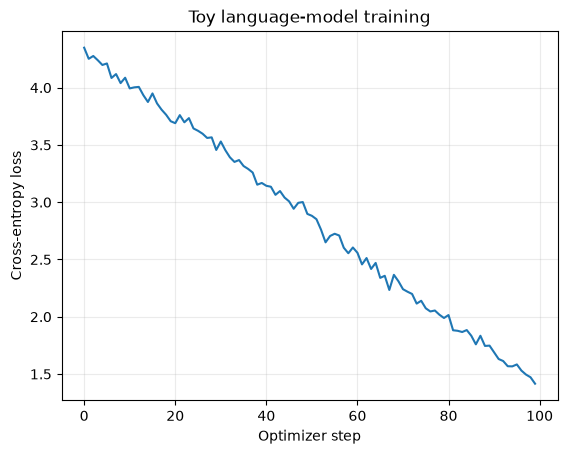

In [6]:
import matplotlib.pyplot as plt

losses = []
grad_norms = []

for step in range(100):
    model.train()
    x, y = get_batch()
    optimizer.zero_grad(set_to_none=True)

    logits = model(x)
    loss = F.cross_entropy(logits.reshape(-1, V), y.reshape(-1))
    loss.backward()

    grad_norm = torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=float("inf"),
    )
    optimizer.step()

    losses.append(loss.item())
    grad_norms.append(grad_norm.item())

    if step % 10 == 0:
        print(
            f"step={step:03d} "
            f"loss={loss.item():.4f} "
            f"grad_norm={grad_norm.item():.4f}"
        )

plt.plot(losses)
plt.xlabel("Optimizer step")
plt.ylabel("Cross-entropy loss")
plt.title("Toy language-model training")
plt.grid(alpha=0.25)
plt.show()

## 6. Inspect norms and optimizer state

Parameters, gradients, and AdamW buffers are different kinds of state. This utility computes global L2 norms for the first two.

In [7]:
def global_norm(tensors):
    values = [
        tensor.detach().float().norm(2)
        for tensor in tensors
        if tensor is not None
    ]
    if not values:
        return 0.0
    return torch.linalg.vector_norm(torch.stack(values), ord=2).item()


# Compute after loss.backward() in a training step.
grad_norm = global_norm(p.grad for p in model.parameters())
weight_norm = global_norm(model.parameters())
learning_rate = optimizer.param_groups[0]["lr"]

print("Gradient norm:", grad_norm)
print("Weight norm:", weight_norm)
print("Learning rate:", learning_rate)

state_entries = sum(len(state) for state in optimizer.state.values())
print("Optimizer state entries:", state_entries)

Gradient norm: 0.7755035758018494
Weight norm: 54.76166534423828
Learning rate: 0.001
Optimizer state entries: 87


## Exercises

1. Comment out `loss.backward()` and verify that the weights stop changing.
2. Comment out `optimizer.step()` and verify that gradients are present but parameters do not update.
3. Remove `optimizer.zero_grad()` and observe gradient accumulation.
4. Increase the learning rate and compare the loss and gradient-norm curves.

Reset the model and optimizer before comparing experiments so that each run starts from the same state.